This is the data reading

216 molecules, 5 active, 211 inactive
majority baseline: 0.977
atoms per molecule: median 24  max 44
[[0. 1. 0. ... 0. 0. 0.]
 [1. 0. 1. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 1. 0.]]

example: CCN(CC)CCOC(=O)c1ccc(N/C=C(/C#N)c2nc(-c3cc4ccccc4oc3=O)cs2)cc1
  a is (37, 37) -> 40 bonds
  x is (37, 14) -> one row per atom, 14 features each


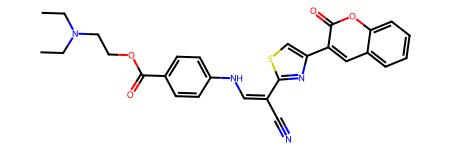

In [ ]:
!pip install -q rdkit

import csv, numpy as np
from google.colab import files
from rdkit import Chem

# uploaded = files.upload()
# path = list(uploaded)[0]
path = "/content/B_lactamase.csv"  #switched to specific loaded file
elements = ["C", "N", "O", "S", "F", "Cl", "Br", "P"]

def atom_features(atom):
    # one-hot for the element, then a few chemical properties
    symbol = atom.GetSymbol()
    onehot = [float(symbol == e) for e in elements] + [float(symbol not in elements)]
    return onehot + [atom.GetDegree() / 4, float(atom.GetIsAromatic()),
                     float(atom.IsInRing()), float(atom.GetFormalCharge()),
                     atom.GetTotalNumHs() / 4]

def smiles_to_graph(smiles):
    # a = who is bonded to whom, x = one row of features per atom
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    n = mol.GetNumAtoms()
    a = np.zeros((n, n))
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        a[i, j] = a[j, i] = 1
    x = np.array([atom_features(atom) for atom in mol.GetAtoms()])
    return a, x

graphs, labels, smiles_list = [], [], []
for row in csv.DictReader(open(path)):
    graph = smiles_to_graph(row["smiles"])
    if graph is not None:
        graphs.append(graph)
        labels.append(int(row["label"]))
        smiles_list.append(row["smiles"])
labels = np.array(labels)

sizes = [len(x) for _, x in graphs]
print(len(graphs), "molecules,", labels.sum(), "active,", len(labels) - labels.sum(), "inactive")
print("majority baseline:", round(max(labels.mean(), 1 - labels.mean()), 3))
print("atoms per molecule: median", int(np.median(sizes)), " max", max(sizes))

a, x = graphs[4]
print(a)
print("\nexample:", smiles_list[4])
print("  a is", a.shape, "->", int(a.sum() // 2), "bonds")
print("  x is", x.shape, "-> one row per atom, 14 features each")
Chem.MolFromSmiles(smiles_list[4])   # Colab draws it

Using PyGame

[[0. 1. 0. ... 0. 0. 0.]
 [1. 0. 1. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 1. 0.]]


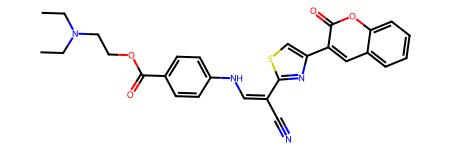

In [ ]:
chem = 4
a, x = graphs[chem]
print(a)
Chem.MolFromSmiles(smiles_list[chem])

[[0. 1. 0. ... 0. 0. 0.]
 [1. 0. 1. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 1. 0.]]
33 atoms, 36 bonds


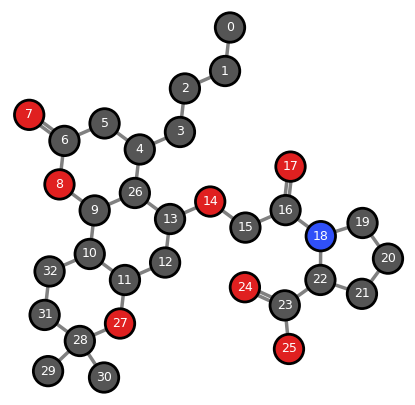

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import AllChem
chem = 6
a, x = graphs[chem]
print(a)
edges = []
for i, row in enumerate(a):
  for j, spot in enumerate(row):
    if spot == 1:
      edges.append((i,j))


smiles = smiles_list[chem]
mol = Chem.MolFromSmiles(smiles)
AllChem.Compute2DCoords(mol)

a = Chem.GetAdjacencyMatrix(mol)
n = mol.GetNumAtoms()
print(n, "atoms,", int(a.sum() // 2), "bonds")
for bond in mol.GetBonds():
    i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
    # print(i, mol.GetAtomWithIdx(i).GetSymbol(), "-", j,
    #       mol.GetAtomWithIdx(j).GetSymbol(), bond.GetBondType())

conf = mol.GetConformer()
get_coord = []
for i in range(n):
    get_coord.append([conf.GetAtomPosition(i).x, -conf.GetAtomPosition(i).y])
coords = np.array(get_coord)

palette = {"C": "#555555", "N": "#3050F8", "O": "#E02020", "S": "#E0C020"}
colors = [palette.get(atom.GetSymbol(), "#BB88DD") for atom in mol.GetAtoms()]


def draw_bond(ax, p, q, order):
    d = q - p
    normal = np.array([-d[1], d[0]]) / np.linalg.norm(d)
    offsets = {1: [0], 2: [-0.07, 0.07], 3: [-0.12, 0, 0.12]}[order]
    for o in offsets:
        s, e = p + normal * o, q + normal * o
        ax.plot([s[0], e[0]], [s[1], e[1]], color="gray", linewidth=2.5, zorder=1)


fig, ax = plt.subplots(figsize=(11, 5))

for bond in mol.GetBonds():
    i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
    order = int(bond.GetBondTypeAsDouble()) or 1
    draw_bond(ax, coords[i], coords[j], order)

ax.scatter(coords[:, 0], coords[:, 1], s=450, color=colors,
           edgecolors="black", linewidths=2, zorder=2)

for atom in mol.GetAtoms():
    i = atom.GetIdx()
    ax.text(coords[i, 0], coords[i, 1], str(i), color="white",
            ha="center", va="center", fontsize=9, zorder=3)

ax.set_aspect("equal")
ax.axis("off")
plt.show()

In [ ]:
import sys
import pygame
from collections import defaultdict
a, x = graphs[0]
print(a)
edges = []
for i, row in enumerate(a):
  for j, spot in enumerate(row):
    if spot == 1:
      edges.append((i,j))

n = len(edges)
print(edges)
a = np.zeros((n, n))
for i, j in edges:
    a[i, j] = a[j, i] = 1

rng = np.random.default_rng(0)
pos = rng.random((n, 2))
for step in range(500):
    diff = pos[:, None, :] - pos[None, :, :]
    dist = np.linalg.norm(diff, axis=-1) + 0.01
    push = (diff / dist[..., None] ** 2).sum(axis=1) * 0.01
    pull = -(a[..., None] * diff).sum(axis=1) * 0.1
    pos += np.clip(push + pull, -0.05, 0.05)

pos -= pos.min(axis=0)
pos /= pos.max(axis=0)
W, H, margin = 800, 600, 60
screen_pos = pos * [W - 2 * margin, H - 2 * margin] + margin

pygame.init()
screen = pygame.display.set_mode((W, H))
pygame.display.set_caption("Molecule graph")
font = pygame.font.SysFont(None, 24)
clock = pygame.time.Clock()

running = True
while running:
    for event in pygame.event.get():
        if event.type == pygame.QUIT:
            running = False

    screen.fill((255, 255, 255))

    for i in range(n):
        for j in range(i + 1, n):
            if a[i, j]:
                pygame.draw.line(screen, (120, 120, 120), screen_pos[i], screen_pos[j], 3)

    for i in range(n):
        x, y = screen_pos[i]
        pygame.draw.circle(screen, (70, 130, 220), (int(x), int(y)), 16)
        label = font.render(str(i), True, (255, 255, 255))
        screen.blit(label, label.get_rect(center=(int(x), int(y))))

    pygame.display.flip()
    clock.tick(30)

pygame.quit()

[[0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0.

KeyboardInterrupt: 

This is training the GNN

In [ ]:
import numpy as np

a_hat = a + np.eye(a.shape[0])
M = a_hat @ x
d_hat = np.diag(np.sum(a_hat, axis = 1))
print("degree matrix:\n", d_hat)
d_hat_inv_sqrt = np.linalg.inv(d_hat)**0.5
a_norm = d_hat_inv_sqrt @ a_hat @ d_hat_inv_sqrt
print("normalized adjacency matrix:\n", a_norm)

degree matrix:
 [[2. 0. 0. ... 0. 0. 0.]
 [0. 3. 0. ... 0. 0. 0.]
 [0. 0. 4. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 3. 0. 0.]
 [0. 0. 0. ... 0. 3. 0.]
 [0. 0. 0. ... 0. 0. 3.]]
normalized adjacency matrix:
 [[0.5        0.40824829 0.         ... 0.         0.         0.        ]
 [0.40824829 0.33333333 0.28867513 ... 0.         0.         0.        ]
 [0.         0.28867513 0.25       ... 0.         0.         0.        ]
 ...
 [0.         0.         0.         ... 0.33333333 0.         0.        ]
 [0.         0.         0.         ... 0.         0.33333333 0.33333333]
 [0.         0.         0.         ... 0.         0.33333333 0.33333333]]


In [ ]:
def normalize(a):
  a = a + np.eye(a.shape[0])
  d = np.diag(np.sum(a, axis = 1))
  d = np.linalg.inv(d)**0.5
  return d @ a @ d
normalize(a)


array([[0.5       , 0.40824829, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.40824829, 0.33333333, 0.28867513, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.28867513, 0.25      , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.33333333, 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.33333333,
        0.33333333],
       [0.        , 0.        , 0.        , ..., 0.        , 0.33333333,
        0.33333333]], shape=(37, 37))

In [ ]:
def init_params(n_features, hidden=16, seed=0):
    rng = np.random.default_rng(seed)
    return [rng.normal(0, 1/np.sqrt(n_features), (n_features, hidden)),
            rng.normal(0, 1/np.sqrt(hidden), (hidden, hidden)),
            rng.normal(0, 1/np.sqrt(hidden), hidden), np.zeros(1)]

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

print("ready")

ready


In [ ]:
def forward(ah, x, params):
  w1, w2, w3, b3 = params
  ax = ah @ x
  h1 = np.tanh(ax @ w1)
  ah1 = ah @ h1
  h2 = np.tanh(ah1 @ w2)
  g = h2.mean(axis = 0)
  p = sigmoid (g @ w3 + b3)[0]
  cache = (ax, h1, ah1, h2, g)
  return p, cache



In [ ]:
def loss_fn(p, y, pos_weight = 1.0):
  w = pos_weight if y == 1 else 1.0
  return -(w * y * np.log(p+1e-9) + (1-y)* np.log(1-p + 1e-9))

In [ ]:
def backward(ah, y, params, cache, p, pos_weight = 1.0):
  w1, w2, w3, b3 = params
  ax, h1, ah1, h2, g = cache
  n = len(h2)
  dz = - pos_weight * (1-p) if y == 1 else p
  dw3 = g * dz
  db3 = np.array([dz])
  dg = dz * w3
  dh2 = np.tile(dg/n, (n, 1))
  dpre2 - dh2 * (1 - h2 ** 2)
  dw2 = ah1.T @ dpre2
  dh1 = ah.T @ (dpre2 @ w2.T)
  dpre1 = 1 - h**2
  dw1 = ax.T @ dpre1
  return [dw1, dw2, dw3, db3]


In [ ]:
def train(adj, feats, labels, idx, params, pos_weight = 1.0, epochs = 100, lr = 0.05, log_every = 20):
  for epoch in range(1, epochs +1):
    grads = [np.zeros_like(w) for w in params]
    total = 0.0
    for i in idx:
      p, cache = forward(adj[i], feats[i], params)
      total += loss_fn(p, labels[i], pos_weight)
      for k, gr in enumerate(backward(adj[i], labels[i], params, cache, p, pos_weight)):
        grads[k] += gr/ len(idx)
    for k in range(len(params)):
      params[k] -= lr * grads[k]
    if epoch % log_every == 0:
      print("  epoch", epoch, " loss", round(total / len(idx), 4))
  return params

In [ ]:
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

torch.manual_seed(0)
max_atoms = max(sizes)
n_feats = graphs[0][1].shape[1]

X = torch.zeros(len(graphs), max_atoms, n_feats)
A = torch.zeros(len(graphs), max_atoms, max_atoms)
n_atoms = torch.tensor(sizes, dtype=torch.float)
Y = torch.tensor(labels, dtype=torch.float)

for k, (a, x) in enumerate(graphs):
    n = len(x)
    a = a + np.eye(n)
    d = a.sum(1)
    a = a / np.sqrt(d[:, None] * d[None, :])
    X[k, :n] = torch.tensor(x, dtype=torch.float)
    A[k, :n, :n] = torch.tensor(a, dtype=torch.float)
idx = np.arange(len(graphs))
train_idx, test_idx = train_test_split(idx, test_size=0.2, stratify=labels, random_state=0)

In [ ]:
class SimpleGNN(nn.Module):
    def __init__(self, n_feats, hidden=64):
        super().__init__()
        self.lin1 = nn.Linear(n_feats, hidden)
        self.lin2 = nn.Linear(hidden, hidden)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x, a, n):
        x = torch.relu(a @ self.lin1(x))
        x = torch.relu(a @ self.lin2(x))
        mol = x.sum(1) / n[:, None]
        return self.out(mol).squeeze(-1)

In [ ]:
#add MLP baseline
class MLP(nn.Module):
  def __init__(self, n_feats, hidden=64):
      super().__init__()
      self.lin1 = nn.Linear(n_feats, hidden)
      self.lin2 = nn.Linear(hidden, hidden)
      self.out = nn.Linear(hidden, 1)
  def forward(self, x, a, n):
        x = torch.relu(self.lin1(x))
        x = torch.relu(self.lin2(x))
        mol = x.sum(1) / n[:, None]
        return self.out(mol).squeeze(-1)

In [ ]:
model = SimpleGNN(n_feats)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
pos_weight = (1 - Y[train_idx]).sum() / Y[train_idx].sum()
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

for epoch in range(1, 101):
    model.train()
    np.random.shuffle(train_idx)
    for i in range(0, len(train_idx), 64):
        b = train_idx[i:i+64]
        opt.zero_grad()
        loss = loss_fn(model(X[b], A[b], n_atoms[b]), Y[b])
        loss.backward()
        opt.step()
    if epoch % 10 == 0:
        print("epoch", epoch, "loss", round(loss.item(), 4))

epoch 10 loss 1.9948
epoch 20 loss 1.2691
epoch 30 loss 1.8796
epoch 40 loss 1.8223
epoch 50 loss 1.2416
epoch 60 loss 1.238
epoch 70 loss 0.977
epoch 80 loss 1.4413
epoch 90 loss 1.4147
epoch 100 loss 0.8102


In [ ]:
model.eval()
with torch.no_grad():
    probs = torch.sigmoid(model(X[test_idx], A[test_idx], n_atoms[test_idx]))
print("test AUC:", round(roc_auc_score(Y[test_idx], probs), 3))

test AUC: 0.977
